# MODUL 10 - DASAR-DASAR DETEKSI OBYEK

**Pengolahan Citra dan Visi Komputer**
**Jurusan Teknologi Informasi - Politeknik Negeri Malang**

---

### Identitas:
**Radit Firansah** (NIM: `244107020196`)

---

### D1. Praktikum Deteksi Obyek Dasar

1. Template Matching (6 metode OpenCV)
2. Template Matching manual (tanpa OpenCV) - multiple object
3. Edge Detection (Sobel, Canny, Laplacian)
4. Corner Detection (Harris, Shi-Tomasi)
5. Grid Detection (Hough Transform)
6. Contour Detection

## 1. Import Library dan Akses Folder Gambar

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

IMG = 'Images Object Detection'
print('OpenCV :', cv2.__version__)
print('File   :', sorted(os.listdir(IMG)))

OpenCV : 4.10.0
File   : ['KTM.jpeg', 'animal-template.jpg', 'animal.jpg', 'bahrain-template.jpg', 'bahrain.jpg', 'car-park.jpg', 'cat-and-rabbit.jpg', 'cat-template.jpg', 'cat2_templatejpg.jpg', 'cats_and_bunnies.jpg', 'chess-board.jpg', 'laptop.jpg', 'parking-lot-cars.jpg', 'sudoku.jpg']


## 2. Template Matching - 6 Metode OpenCV

Citra masukan `cats_and_bunnies.jpg`, template `cat2_templatejpg.jpg`. Setiap metode memakai `cv2.matchTemplate()`.

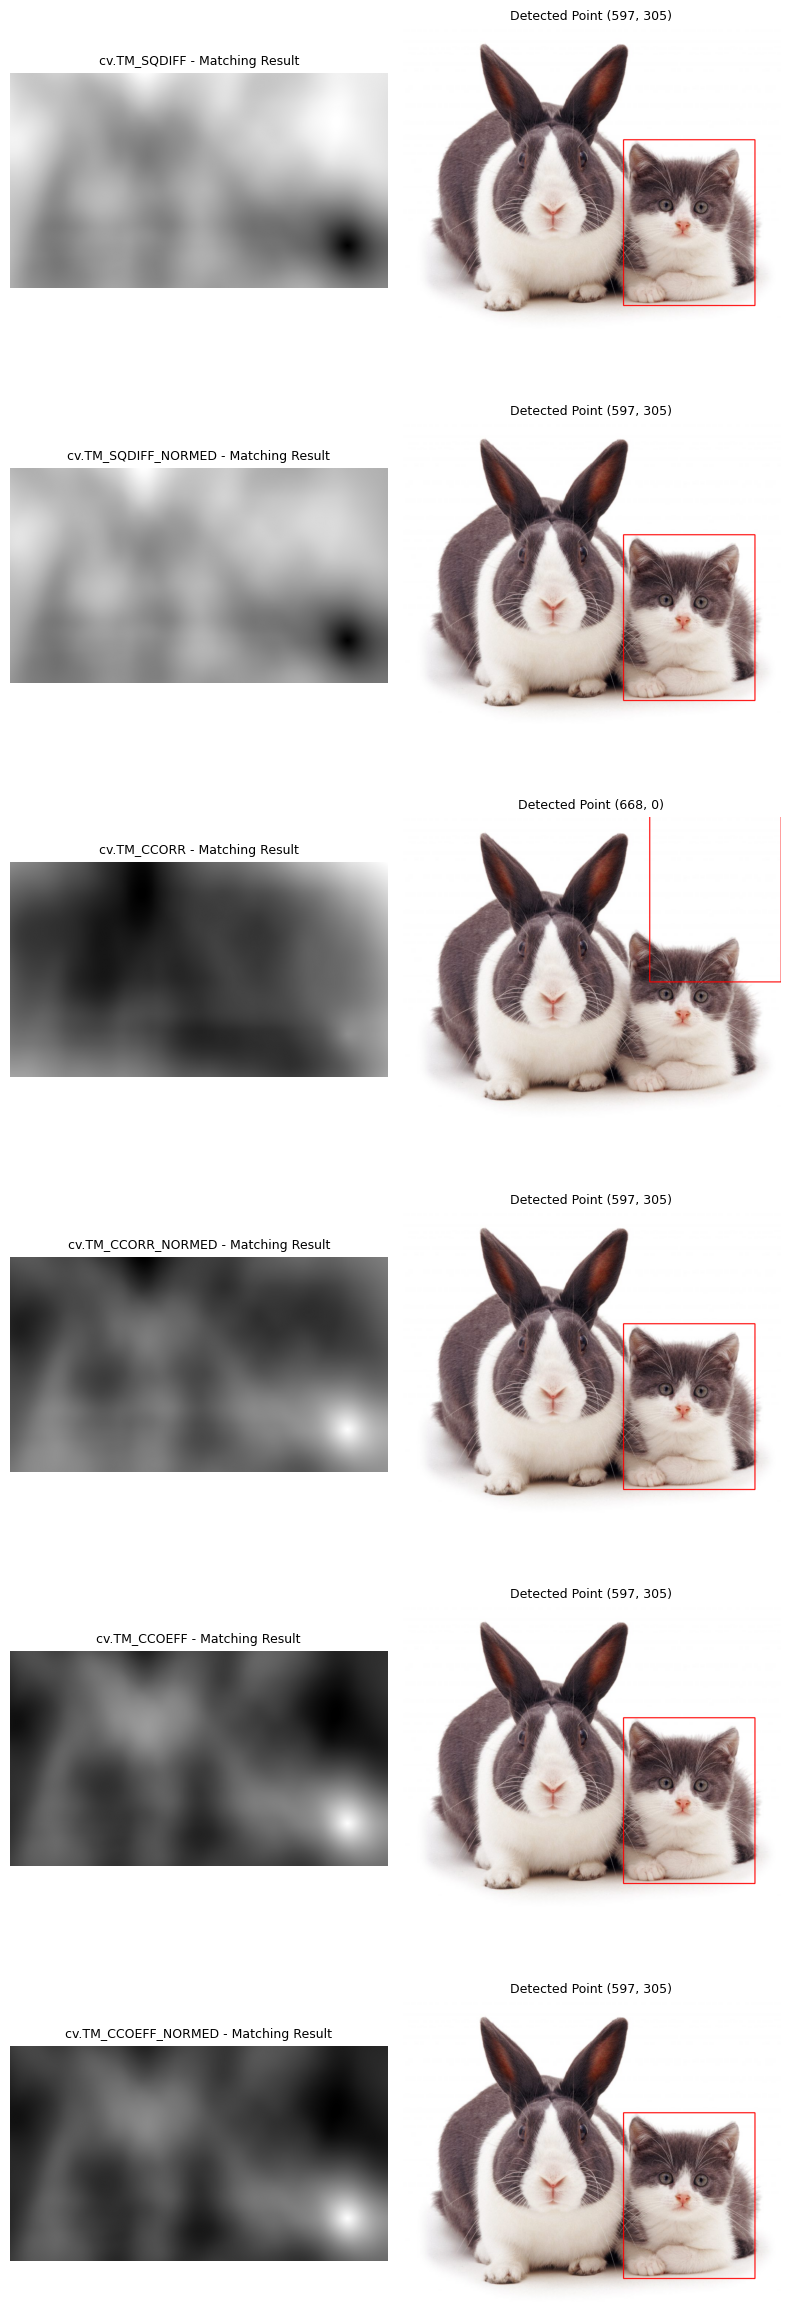

In [2]:
img = cv2.imread(f'{IMG}/cats_and_bunnies.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
tpl = cv2.imread(f'{IMG}/cat2_templatejpg.jpg', 0)
th, tw = tpl.shape

metode = ['TM_SQDIFF', 'TM_SQDIFF_NORMED', 'TM_CCORR',
          'TM_CCORR_NORMED', 'TM_CCOEFF', 'TM_CCOEFF_NORMED']

fig, ax = plt.subplots(6, 2, figsize=(8, 24))
for i, nama in enumerate(metode):
    res = cv2.matchTemplate(gray, tpl, getattr(cv2, nama))
    mn, mx, mn_loc, mx_loc = cv2.minMaxLoc(res)
    loc = mn_loc if 'SQDIFF' in nama else mx_loc
    hasil = img.copy()
    cv2.rectangle(hasil, loc, (loc[0] + tw, loc[1] + th), (0, 0, 255), 2)
    ax[i, 0].imshow(res, cmap='gray')
    ax[i, 0].set_title(f'cv.{nama} - Matching Result', fontsize=9)
    ax[i, 1].imshow(cv2.cvtColor(hasil, cv2.COLOR_BGR2RGB))
    ax[i, 1].set_title(f'Detected Point {loc}', fontsize=9)
    for a in ax[i]:
        a.axis('off')
plt.tight_layout()
plt.show()

## 3. Template Matching Manual (Tanpa OpenCV) - Multiple Object

Citra masukan `bahrain.jpg`, template `bahrain-template.jpg`. Pencocokan memakai **Normalized Cross-Correlation** yang dihitung sendiri dengan NumPy (template digeser ke seluruh posisi citra).

Jumlah objek terdeteksi: 6


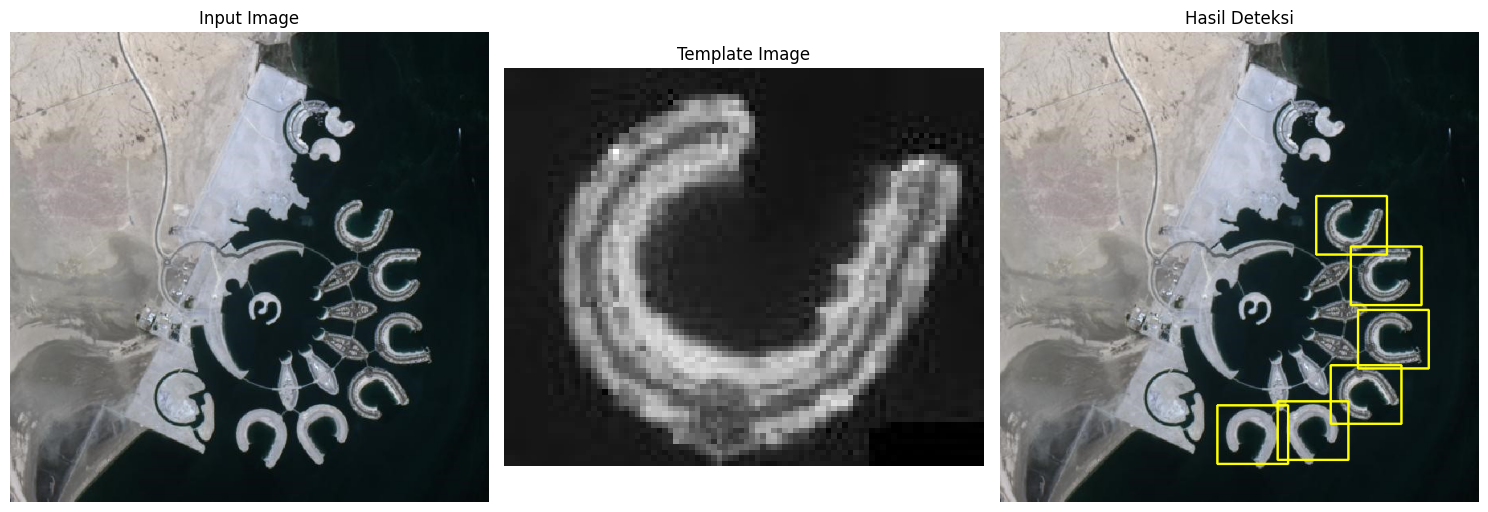

In [3]:
img = cv2.imread(f'{IMG}/bahrain.jpg')
gray = cv2.imread(f'{IMG}/bahrain.jpg', 0).astype(np.float32)
tpl = cv2.imread(f'{IMG}/bahrain-template.jpg', 0).astype(np.float32)
th, tw = tpl.shape

# NCC manual: geser template ke setiap posisi (x, y) citra
tpl0 = tpl - tpl.mean()
tpl_norm = np.sqrt((tpl0 ** 2).sum())
H, W = gray.shape
res = np.zeros((H - th + 1, W - tw + 1), np.float32)
for y in range(H - th + 1):
    win = np.lib.stride_tricks.sliding_window_view(gray[y:y + th], (th, tw))[0]
    win0 = win - win.mean(axis=(1, 2), keepdims=True)
    den = np.sqrt((win0 ** 2).sum(axis=(1, 2))) * tpl_norm
    res[y] = np.where(den > 1e-6, (win0 * tpl0).sum(axis=(1, 2)) / np.maximum(den, 1e-6), 0)

# Ambil kandidat terbaik, buang kotak yang tumpang tindih
ys, xs = np.where(res >= 0.45)
kandidat = sorted(zip(res[ys, xs], ys, xs), reverse=True)
kotak = []
for skor, y, x in kandidat:
    if all(abs(x - kx) > tw * 0.5 or abs(y - ky) > th * 0.5 for _, ky, kx in kotak):
        kotak.append((skor, y, x))

hasil = img.copy()
for skor, y, x in kotak:
    cv2.rectangle(hasil, (x, y), (x + tw, y + th), (0, 255, 255), 2)
print('Jumlah objek terdeteksi:', len(kotak))

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax[0].set_title('Input Image')
ax[1].imshow(tpl, cmap='gray'); ax[1].set_title('Template Image')
ax[2].imshow(cv2.cvtColor(hasil, cv2.COLOR_BGR2RGB)); ax[2].set_title('Hasil Deteksi')
for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()

## 4. Edge Detection

Citra `car-park.jpg` dengan metode **Sobel**, **Canny**, dan **Laplacian**.

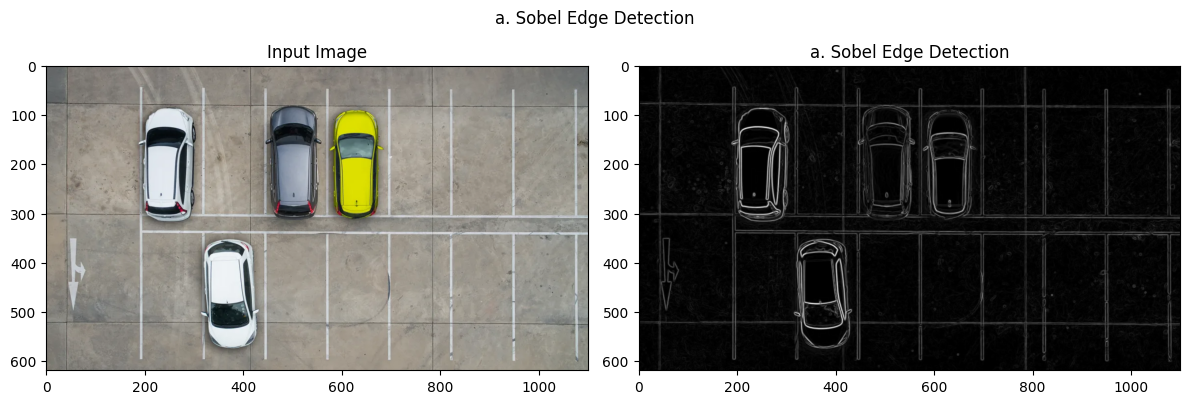

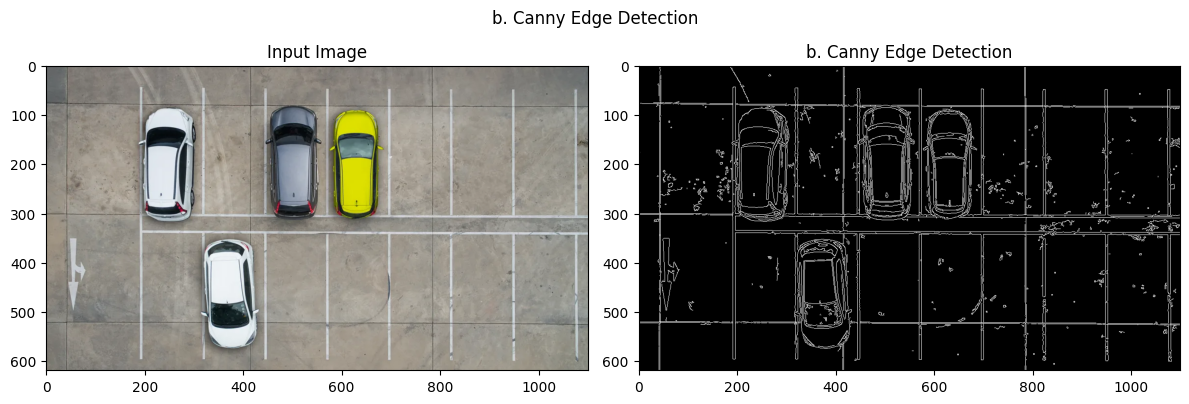

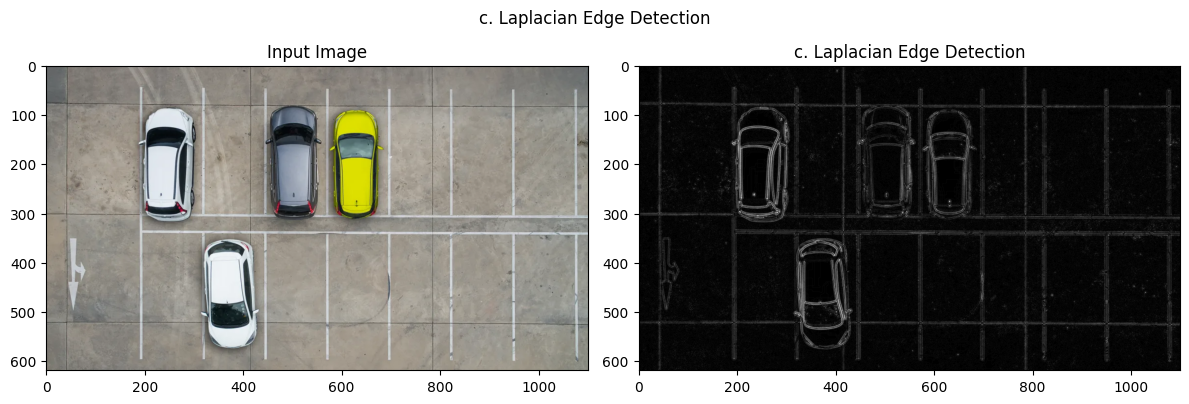

In [4]:
img = cv2.imread(f'{IMG}/car-park.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=5)
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=5)
sobel = np.abs(cv2.magnitude(sobel_x, sobel_y))

canny = cv2.Canny(gray, 50, 150)

blur = cv2.GaussianBlur(gray, (5, 5), 0)
laplacian = np.abs(cv2.Laplacian(blur, cv2.CV_64F))

judul = ['a. Sobel Edge Detection', 'b. Canny Edge Detection', 'c. Laplacian Edge Detection']
for nama, tepi in zip(judul, [sobel, canny, laplacian]):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax[0].set_title('Input Image')
    ax[1].imshow(tepi, cmap='gray'); ax[1].set_title(nama)
    plt.suptitle(nama)
    plt.tight_layout()
    plt.show()

## 5. Corner Detection

Citra `chess-board.jpg` dengan **Harris Corner Detection** dan **Shi-Tomasi**.

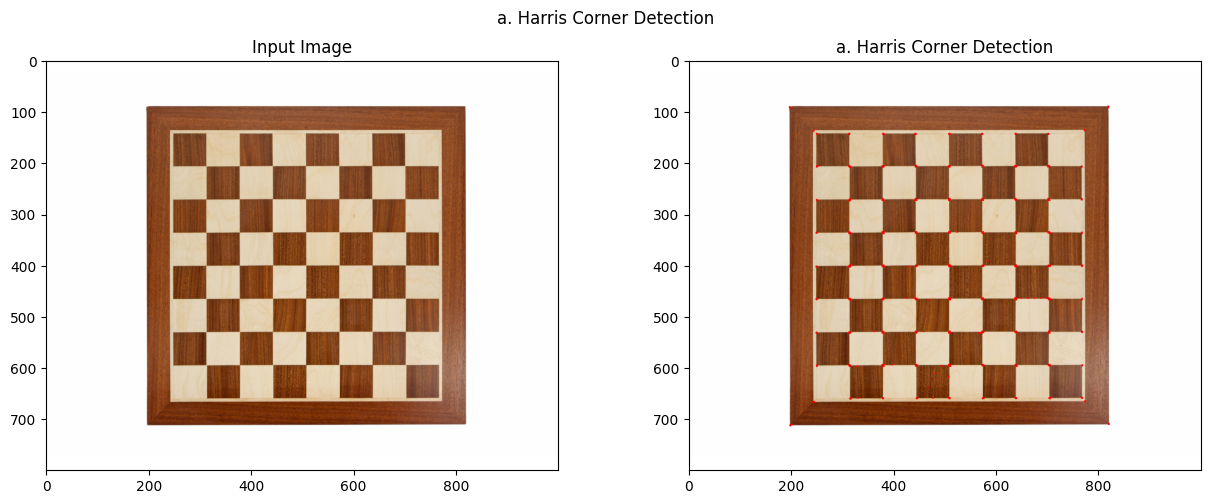

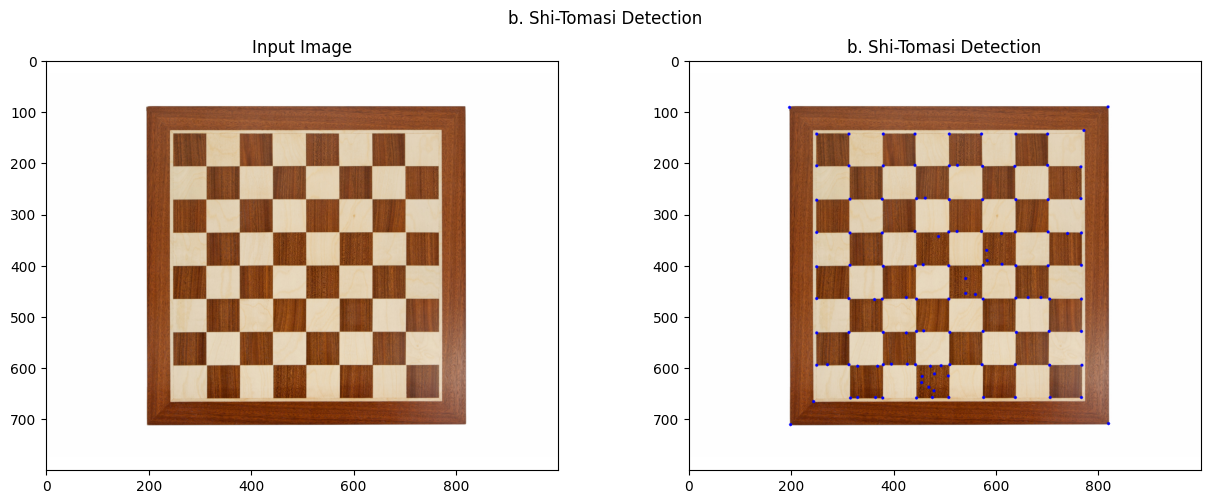

In [5]:
img = cv2.imread(f'{IMG}/chess-board.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Harris
harris = cv2.cornerHarris(np.float32(gray), 2, 3, 0.04)
harris = cv2.dilate(harris, None)
hasil_harris = img.copy()
hasil_harris[harris > 0.005 * harris.max()] = (0, 0, 255)

# Shi-Tomasi
corners = cv2.goodFeaturesToTrack(gray, 120, 0.01, 10)
hasil_shi = img.copy()
for c in corners:
    x, y = c.ravel()
    cv2.circle(hasil_shi, (int(x), int(y)), 3, (255, 0, 0), -1)

for nama, hasil in [('a. Harris Corner Detection', hasil_harris),
                    ('b. Shi-Tomasi Detection', hasil_shi)]:
    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    ax[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax[0].set_title('Input Image')
    ax[1].imshow(cv2.cvtColor(hasil, cv2.COLOR_BGR2RGB)); ax[1].set_title(nama)
    plt.suptitle(nama)
    plt.tight_layout()
    plt.show()

## 6. Grid Detection - Hough Transform

Citra `sudoku.jpg`. Tahapan: Canny -> dilasi -> erosi -> `HoughLines` -> gabungkan garis yang mirip.

Garis Hough: 56 | setelah digabung: 19


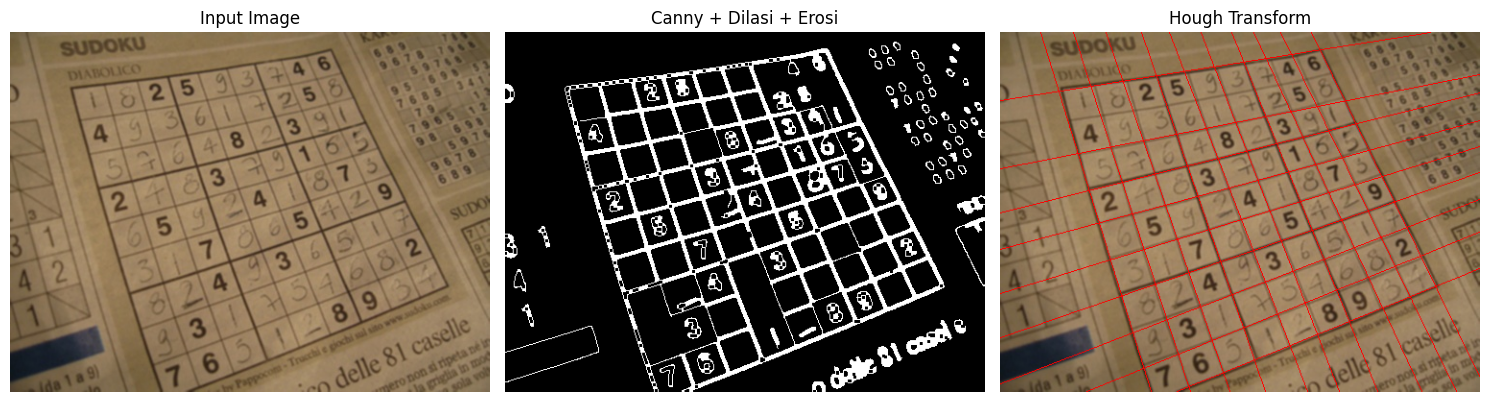

In [6]:
img = cv2.imread(f'{IMG}/sudoku.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

edges = cv2.Canny(cv2.GaussianBlur(gray, (5, 5), 0), 50, 150)
edges = cv2.dilate(edges, np.ones((3, 3), np.uint8), iterations=1)
edges = cv2.erode(edges, np.ones((3, 3), np.uint8), iterations=1)

garis = cv2.HoughLines(edges, 1, np.pi / 180, 200)[:, 0]

# Gabungkan garis yang mirip (rho dan theta berdekatan)
unik = []
for rho, theta in garis:
    if not any(abs(rho - r) < 15 and abs(theta - t) < np.deg2rad(3) for r, t in unik):
        unik.append((rho, theta))

hasil = img.copy()
for rho, theta in unik:
    a, b = np.cos(theta), np.sin(theta)
    x0, y0 = a * rho, b * rho
    cv2.line(hasil,
             (int(x0 + 1000 * -b), int(y0 + 1000 * a)),
             (int(x0 - 1000 * -b), int(y0 - 1000 * a)),
             (0, 0, 255), 1)
print('Garis Hough:', len(garis), '| setelah digabung:', len(unik))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax[0].set_title('Input Image')
ax[1].imshow(edges, cmap='gray'); ax[1].set_title('Canny + Dilasi + Erosi')
ax[2].imshow(cv2.cvtColor(hasil, cv2.COLOR_BGR2RGB)); ax[2].set_title('Hough Transform')
for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()

## 7. Contour Detection

Citra `laptop.jpg` dengan `cv2.findContours()` dan `cv2.drawContours()`. Citra diperkecil dulu agar pemrosesan cepat.

Jumlah kontur: 39


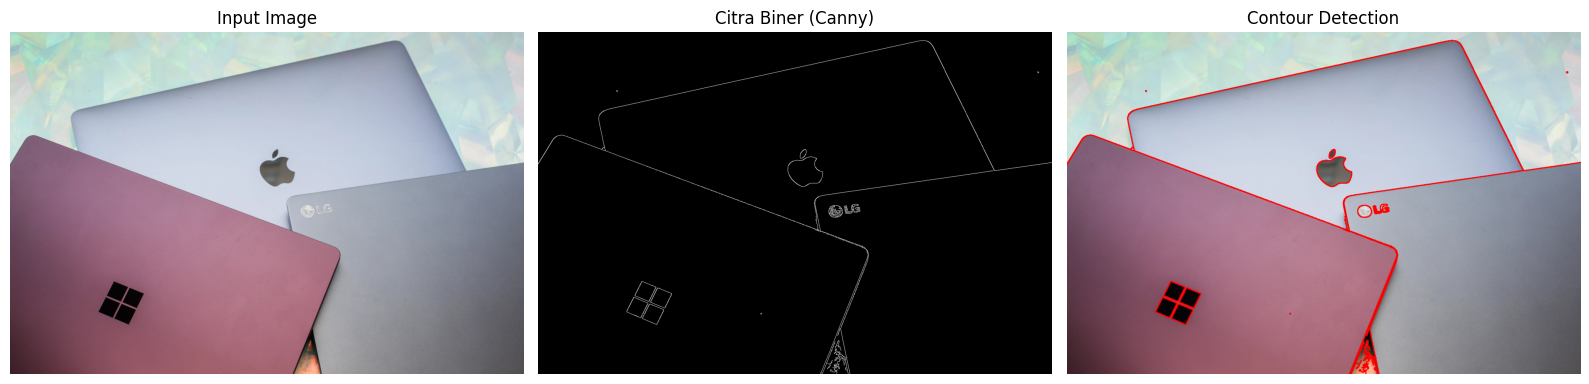

In [7]:
img = cv2.imread(f'{IMG}/laptop.jpg')
img = cv2.resize(img, None, fx=0.35, fy=0.35)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

biner = cv2.Canny(gray, 50, 150)
kontur, hierarki = cv2.findContours(biner, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

hasil = img.copy()
cv2.drawContours(hasil, kontur, -1, (0, 0, 255), 2)
print('Jumlah kontur:', len(kontur))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax[0].set_title('Input Image')
ax[1].imshow(biner, cmap='gray'); ax[1].set_title('Citra Biner (Canny)')
ax[2].imshow(cv2.cvtColor(hasil, cv2.COLOR_BGR2RGB)); ax[2].set_title('Contour Detection')
for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()

---
# D2. Praktikum Feature Matching dan Face Detection

> Catatan: folder `images/facedet` dan `images/people` tidak tersedia pada direktori ini,
> sehingga face detection memakai citra yang ada: `prabowo.jpg` dan `Images Object Detection/KTM.jpeg`.
> Pretrained Haar Cascade disalin ke folder `haarcascades/`.

## 8. Face Detection

Menggunakan `haarcascade_frontalface_alt.xml` dan `detectMultiScale()`.

prabowo.jpg -> 1 wajah
Images Object Detection/KTM.jpeg -> 1 wajah


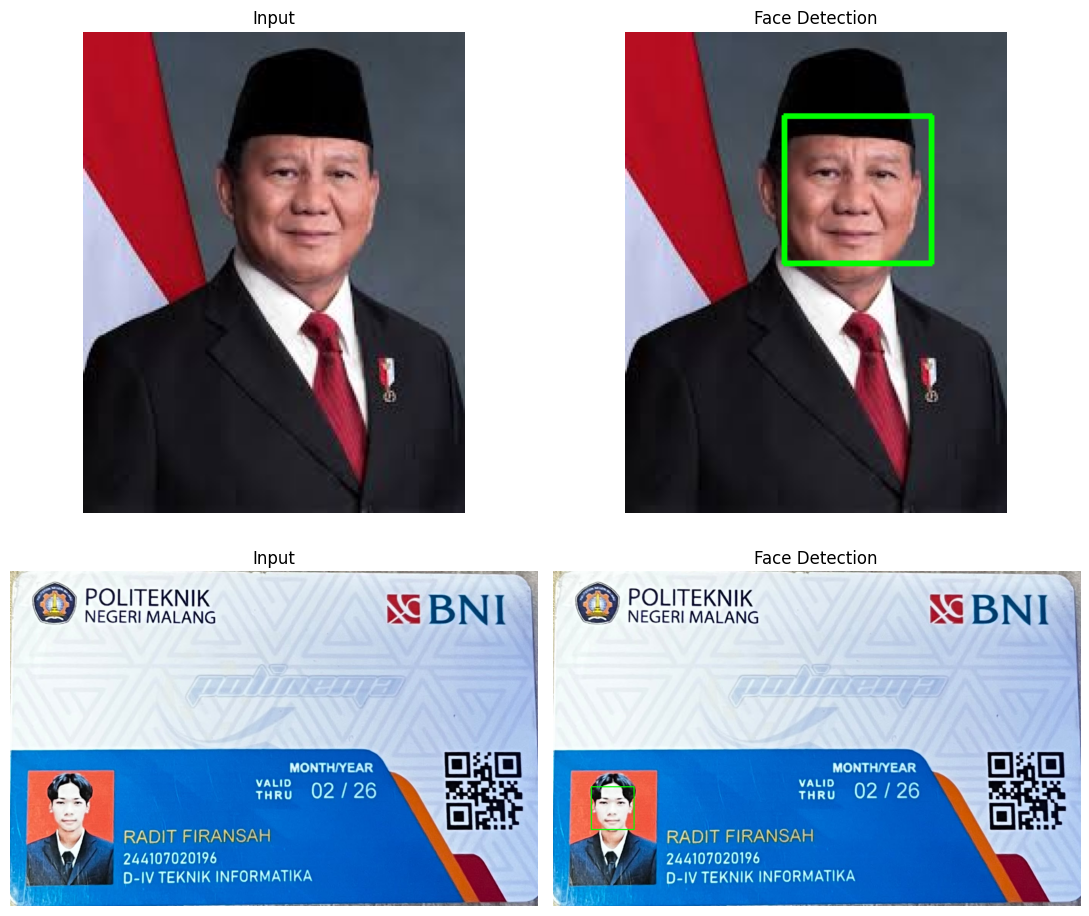

In [8]:
H = 'haarcascades/'
cascade_wajah = cv2.CascadeClassifier(H + 'haarcascade_frontalface_alt.xml')
cascade_mata = cv2.CascadeClassifier(H + 'haarcascade_eye.xml')
cascade_senyum = cv2.CascadeClassifier(H + 'haarcascade_smile.xml')
cascade_kucing = cv2.CascadeClassifier(H + 'haarcascade_frontalcatface.xml')

daftar = ['prabowo.jpg', f'{IMG}/KTM.jpeg']
fig, ax = plt.subplots(len(daftar), 2, figsize=(11, 5 * len(daftar)))
for i, nama in enumerate(daftar):
    img = cv2.imread(nama)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    roi_wajah = cascade_wajah.detectMultiScale(gray, 1.1, 5)
    hasil = img.copy()
    for (x, y, w, h) in roi_wajah:
        cv2.rectangle(hasil, (x, y), (x + w, y + h), (0, 255, 0), 2)
    print(nama, '->', len(roi_wajah), 'wajah')
    ax[i, 0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax[i, 0].set_title('Input')
    ax[i, 1].imshow(cv2.cvtColor(hasil, cv2.COLOR_BGR2RGB)); ax[i, 1].set_title('Face Detection')
    for a in ax[i]:
        a.axis('off')
plt.tight_layout()
plt.show()

## 9. Deteksi Wajah Kucing

Memakai pretrained `haarcascade_frontalcatface.xml` yang sudah disediakan OpenCV. Wajah kucing tidak terdeteksi oleh cascade wajah manusia, jadi perlu cascade khusus kucing.

Wajah kucing terdeteksi: 1


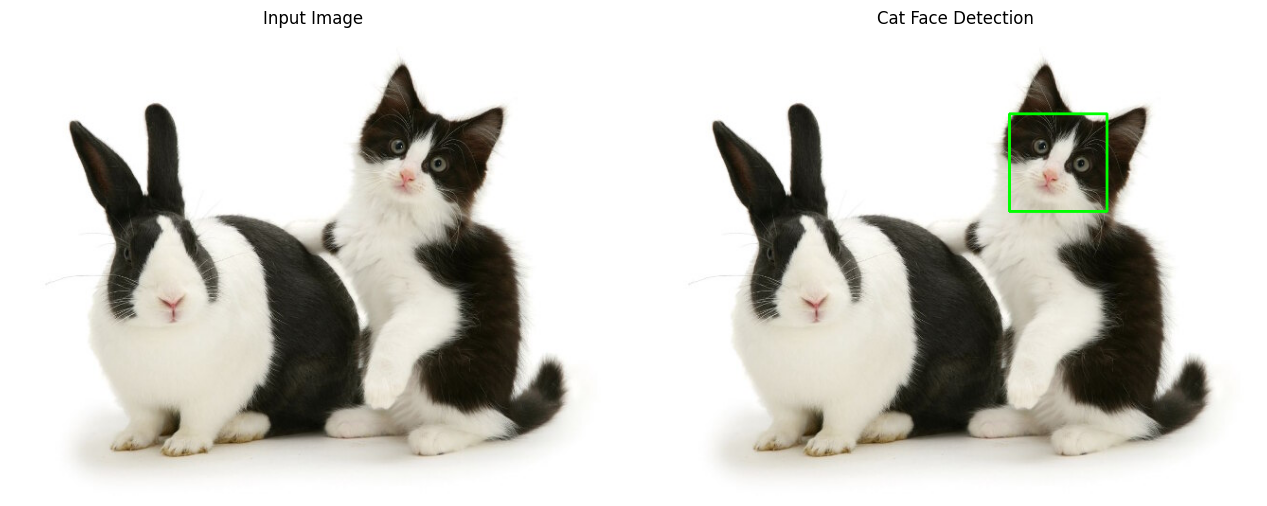

In [9]:
img = cv2.imread(f'{IMG}/cat-and-rabbit.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

roi_kucing = cascade_kucing.detectMultiScale(gray, 1.04, 3, minSize=(40, 40))
hasil = img.copy()
for (x, y, w, h) in roi_kucing:
    cv2.rectangle(hasil, (x, y), (x + w, y + h), (0, 255, 0), 2)
print('Wajah kucing terdeteksi:', len(roi_kucing))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax[0].set_title('Input Image')
ax[1].imshow(cv2.cvtColor(hasil, cv2.COLOR_BGR2RGB)); ax[1].set_title('Cat Face Detection')
for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()

## 10. Eyes Detection pada Wajah Pak Prabowo

Mata terdeteksi: 2


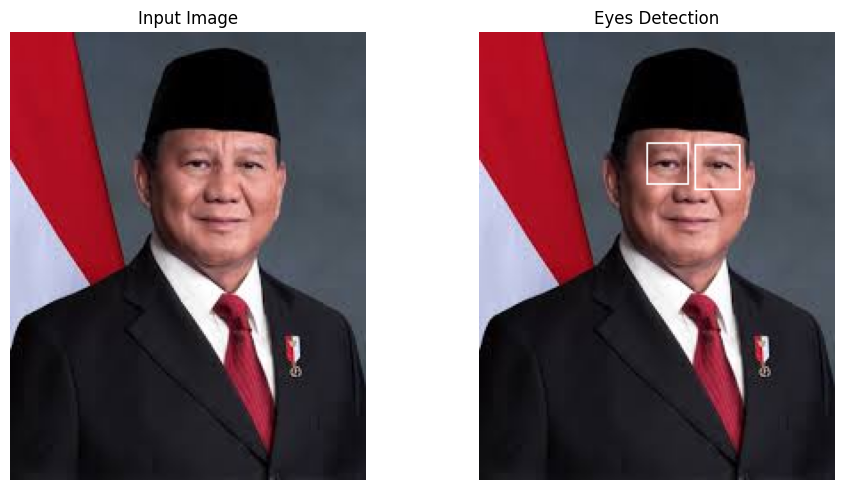

In [10]:
img = cv2.imread('prabowo.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

(x, y, w, h) = cascade_wajah.detectMultiScale(gray, 1.1, 5)[0]
roi = gray[y:y + int(h * 0.6), x:x + w]          # area mata ada di bagian atas wajah
roi_mata = cascade_mata.detectMultiScale(roi, 1.05, 3, minSize=(10, 10))

hasil = img.copy()
for (ex, ey, ew, eh) in roi_mata:
    cv2.rectangle(hasil, (x + ex, y + ey), (x + ex + ew, y + ey + eh), (255, 255, 255), 1)
print('Mata terdeteksi:', len(roi_mata))

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax[0].set_title('Input Image')
ax[1].imshow(cv2.cvtColor(hasil, cv2.COLOR_BGR2RGB)); ax[1].set_title('Eyes Detection')
for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()

## 11. Deteksi Senyuman

`haarcascade_smile.xml` dijalankan di dalam area wajah yang sudah terdeteksi.

Senyuman terdeteksi: 1


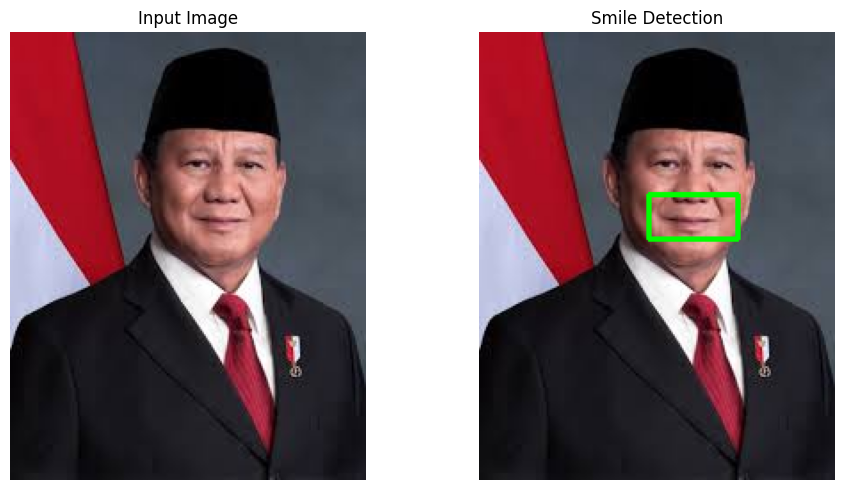

In [11]:
img = cv2.imread('prabowo.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

(x, y, w, h) = cascade_wajah.detectMultiScale(gray, 1.1, 5)[0]
roi = gray[y:y + h, x:x + w]
roi_senyum = cascade_senyum.detectMultiScale(roi, 1.3, 15)

hasil = img.copy()
for (sx, sy, sw, sh) in roi_senyum:
    cv2.rectangle(hasil, (x + sx, y + sy), (x + sx + sw, y + sy + sh), (0, 255, 0), 2)
print('Senyuman terdeteksi:', len(roi_senyum))

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax[0].set_title('Input Image')
ax[1].imshow(cv2.cvtColor(hasil, cv2.COLOR_BGR2RGB)); ax[1].set_title('Smile Detection')
for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()

## 12. Face Tracking

Webcam lokal dibaca frame demi frame lalu wajah dideteksi pada setiap frame (face tracking).
Jika kamera tidak memberi gambar (mis. diblokir), dipakai urutan frame sintetis hasil pan dari
`prabowo.jpg` agar proses tracking tetap terlihat.

Kamera tidak memberi gambar - memakai frame sintetis (pan gambar prabowo).


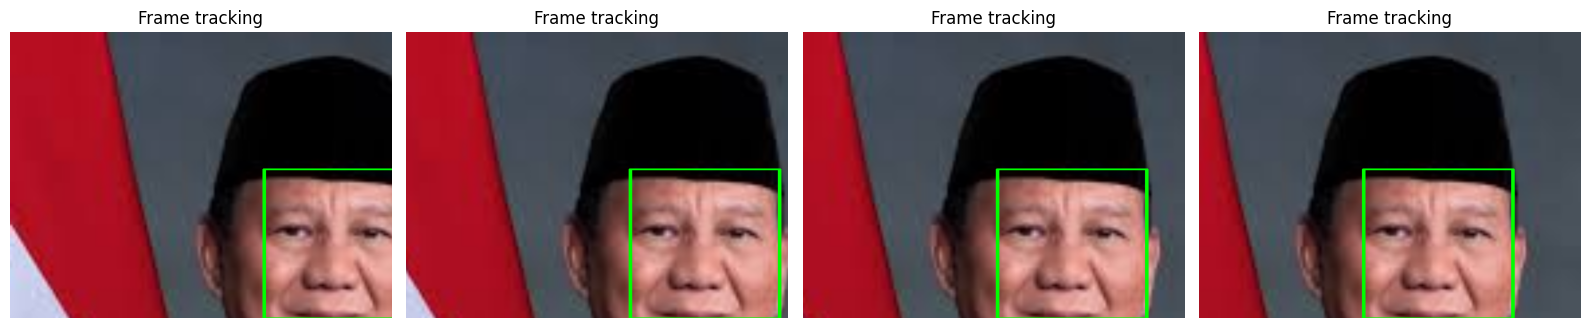

In [12]:
cap = cv2.VideoCapture(0)
frames = []
for _ in range(60):
    ok, frame = cap.read()
    if not ok:
        break
    frames.append(frame)
cap.release()

if len(frames) == 0 or max(f.mean() for f in frames) < 20:
    print('Kamera tidak memberi gambar - memakai frame sintetis (pan gambar prabowo).')
    sumber = cv2.resize(cv2.imread('prabowo.jpg'), (900, 1134))
    frames = [sumber[0:480, i * 5:i * 5 + 640] for i in range(40)]
else:
    print('Face tracking dari webcam:', len(frames), 'frame')

contoh = []
for i, frame in enumerate(frames):
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    for (x, y, w, h) in cascade_wajah.detectMultiScale(gray, 1.1, 5):
        cv2.rectangle(frame, (x, y), (x + w, y + h), (0, 255, 0), 2)
    if i % 10 == 0:
        contoh.append(frame)

fig, ax = plt.subplots(1, len(contoh), figsize=(4 * len(contoh), 3.5))
for a, frame in zip(np.atleast_1d(ax), contoh):
    a.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    a.set_title('Frame tracking')
    a.axis('off')
plt.tight_layout()
plt.show()

## 13. Blurring pada Wajah yang Terdeteksi

Area wajah di-blur dengan `cv2.medianBlur`.

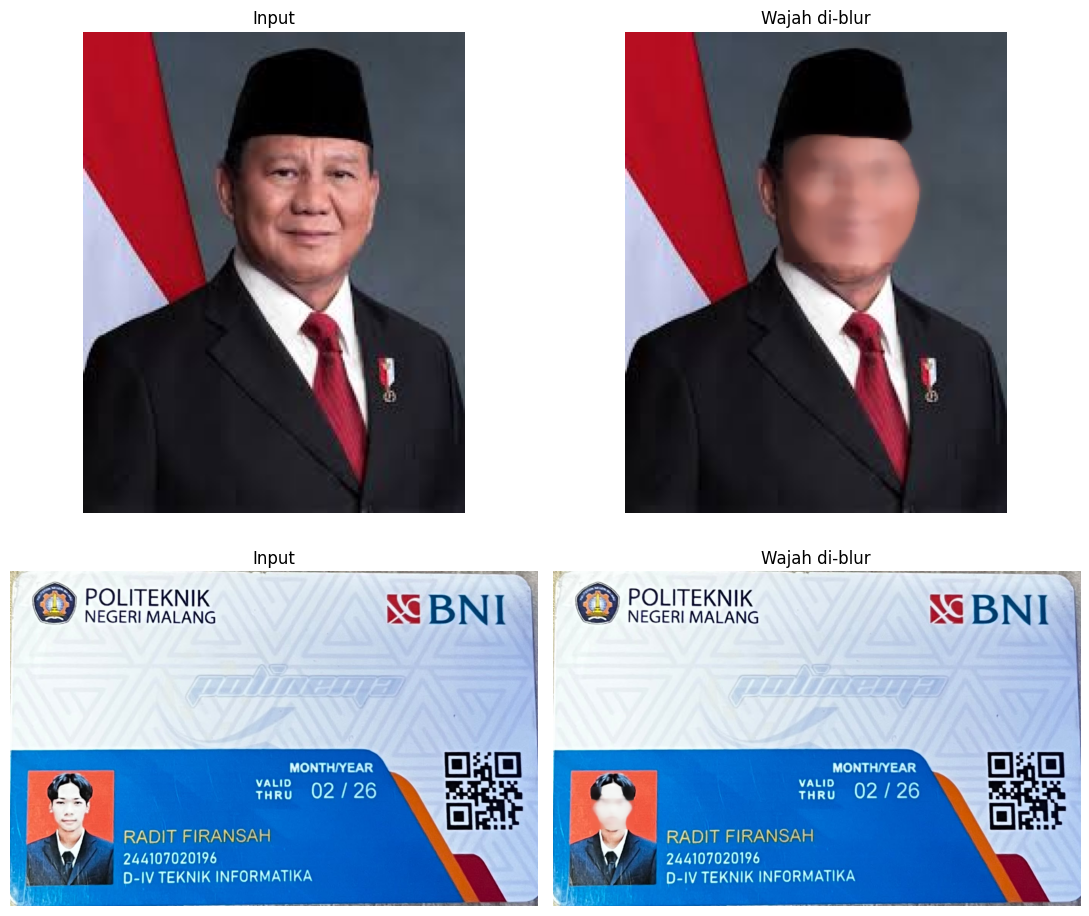

In [13]:
daftar = ['prabowo.jpg', f'{IMG}/KTM.jpeg']
fig, ax = plt.subplots(len(daftar), 2, figsize=(11, 5 * len(daftar)))
for i, nama in enumerate(daftar):
    img = cv2.imread(nama)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    hasil = img.copy()
    for (x, y, w, h) in cascade_wajah.detectMultiScale(gray, 1.1, 5):
        k = max(3, (min(w, h) // 5) | 1)          # ukuran blur harus ganjil
        hasil[y:y + h, x:x + w] = cv2.medianBlur(hasil[y:y + h, x:x + w], k)
    ax[i, 0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax[i, 0].set_title('Input')
    ax[i, 1].imshow(cv2.cvtColor(hasil, cv2.COLOR_BGR2RGB)); ax[i, 1].set_title('Wajah di-blur')
    for a in ax[i]:
        a.axis('off')
plt.tight_layout()
plt.show()

## 14. Mengolah Gambar KTM

### a. Tampilkan Foto KTM

Ukuran KTM: (878, 1384, 3)


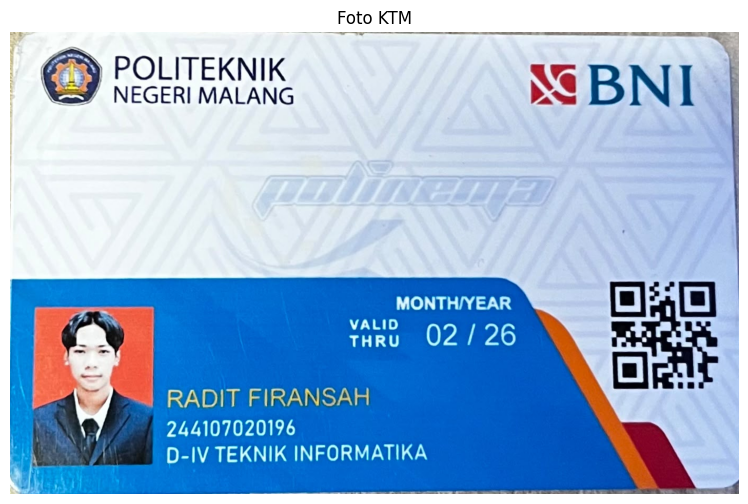

In [14]:
ktm = cv2.imread(f'{IMG}/KTM.jpeg')
print('Ukuran KTM:', ktm.shape)
plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(ktm, cv2.COLOR_BGR2RGB))
plt.title('Foto KTM')
plt.axis('off')
plt.show()

### b. Crop Foto pada KTM

Foto pemilik berada pada latar merah, sehingga dideteksi lewat threshold warna HSV lalu di-crop.

Lokasi foto: (45, 524, 227, 191)


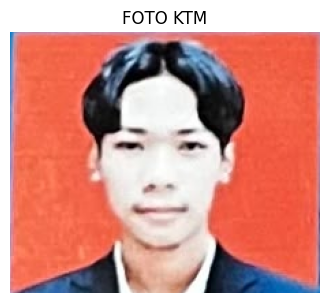

In [15]:
h, w = ktm.shape[:2]
hsv = cv2.cvtColor(ktm, cv2.COLOR_BGR2HSV)

# Ambil area merah (foto) pada bagian kiri-bawah kartu
mask = cv2.inRange(hsv, (0, 100, 60), (12, 255, 255)) | cv2.inRange(hsv, (168, 100, 60), (180, 255, 255))
mask[:int(h * 0.45)] = 0
mask[:, int(w * 0.4):] = 0
mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((25, 25), np.uint8))

kontur, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
(x, y, cw, ch) = cv2.boundingRect(max(kontur, key=cv2.contourArea))
foto_ktm = ktm[y:y + ch, x:x + cw]
print('Lokasi foto:', (x, y, cw, ch))

plt.figure(figsize=(4, 5))
plt.imshow(cv2.cvtColor(foto_ktm, cv2.COLOR_BGR2RGB))
plt.title('FOTO KTM')
plt.axis('off')
plt.show()

### c. Deteksi Obyek KTM dengan Feature Matching

KTM ditempelkan pada citra lain (disimulasikan, karena folder tidak menyediakan foto KTM
bersama barang lain), lalu dicari kembali memakai **ORB**, **SIFT + ratio test**, dan
**homography** untuk menggambar batas KTM.

ORB keypoint: 500 500 | match: 500


SIFT match lolos ratio test: 1009


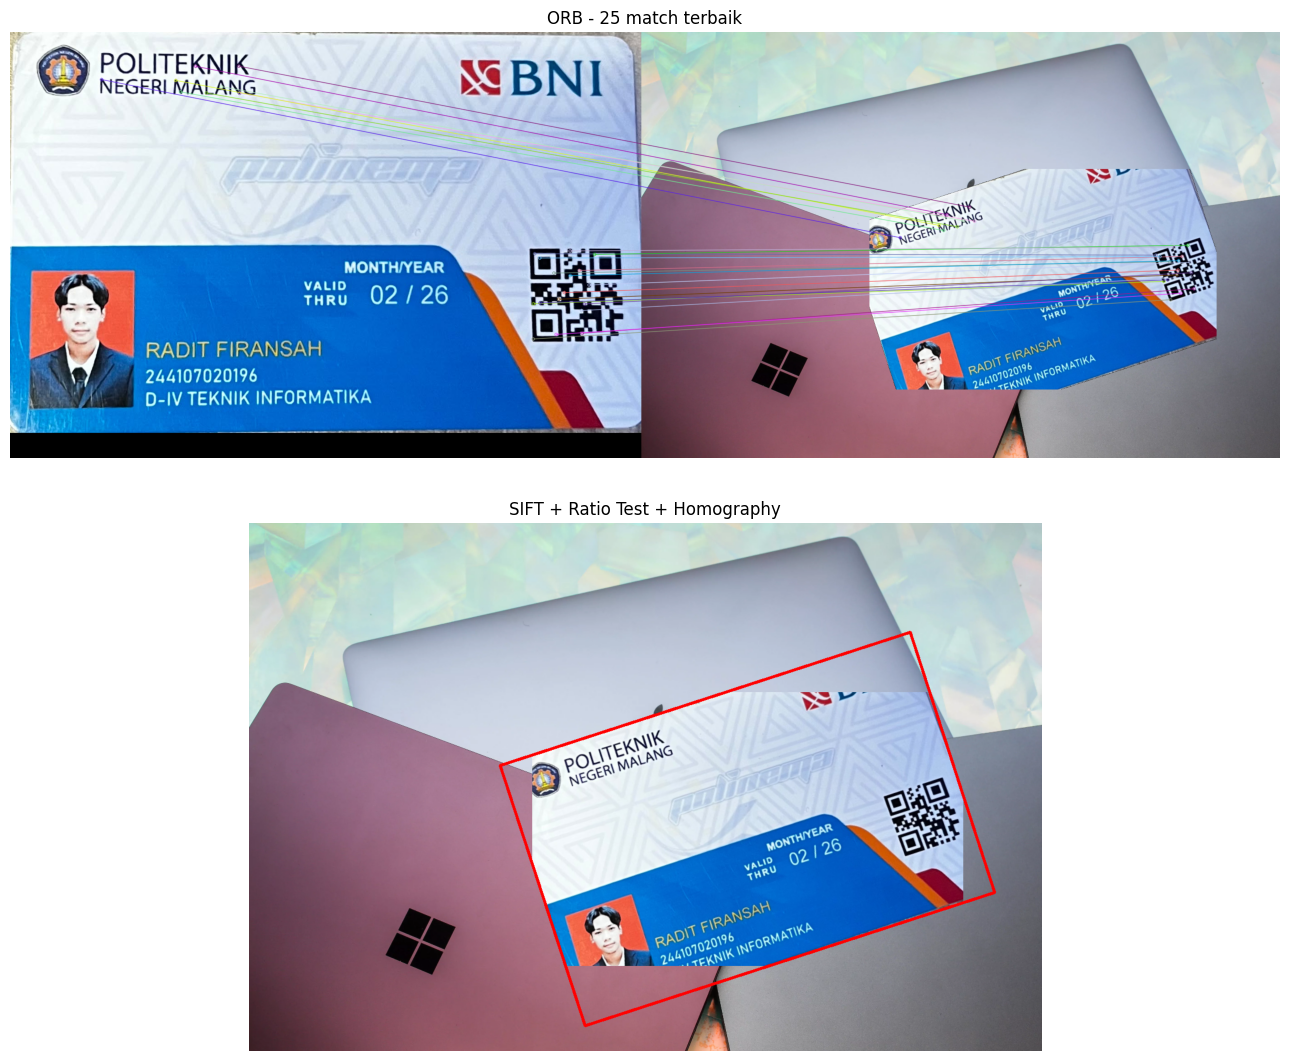

In [16]:
# Scene simulasi: KTM dirotasi & diperkecil, ditempel pada citra lain
latar = cv2.resize(cv2.imread(f'{IMG}/laptop.jpg'), (1400, 933))
kecil = cv2.resize(ktm, None, fx=0.55, fy=0.55)
kh, kw = kecil.shape[:2]
M = cv2.getRotationMatrix2D((kw / 2, kh / 2), 18, 1.0)
kecil = cv2.warpAffine(kecil, M, (kw, kh))
scene = latar.copy()
area = scene[300:300 + kh, 500:500 + kw]
tampak = kecil.sum(axis=2) > 0
area[tampak] = kecil[tampak]
cv2.imwrite('scene_ktm.jpg', scene)

gray_ktm = cv2.cvtColor(ktm, cv2.COLOR_BGR2GRAY)
gray_scene = cv2.cvtColor(scene, cv2.COLOR_BGR2GRAY)

# ORB
orb = cv2.ORB_create()
kp1, d1 = orb.detectAndCompute(gray_ktm, None)
kp2, d2 = orb.detectAndCompute(gray_scene, None)
cocok_orb = cv2.BFMatcher(cv2.NORM_HAMMING).match(d1, d2)
hasil_orb = cv2.drawMatches(ktm, kp1, scene, kp2, sorted(cocok_orb, key=lambda m: m.distance)[:25],
                            None, flags=2)
print('ORB keypoint:', len(kp1), len(kp2), '| match:', len(cocok_orb))

# SIFT + ratio test
sift = cv2.SIFT_create()
kp1, d1 = sift.detectAndCompute(gray_ktm, None)
kp2, d2 = sift.detectAndCompute(gray_scene, None)
pasangan = cv2.BFMatcher().knnMatch(d1, d2, k=2)
baik = [m for m, n in pasangan if m.distance < 0.75 * n.distance]
print('SIFT match lolos ratio test:', len(baik))

# Homography -> kotak KTM pada scene
src = np.float32([kp1[m.queryIdx].pt for m in baik]).reshape(-1, 1, 2)
dst = np.float32([kp2[m.trainIdx].pt for m in baik]).reshape(-1, 1, 2)
H, _ = cv2.findHomography(src, dst, cv2.RANSAC, 5.0)
sudut = np.float32([[0, 0], [ktm.shape[1], 0], [ktm.shape[1], ktm.shape[0]], [0, ktm.shape[0]]]).reshape(-1, 1, 2)
batas = cv2.perspectiveTransform(sudut, H).astype(int)
hasil_sift = scene.copy()
cv2.polylines(hasil_sift, [batas], True, (0, 0, 255), 4)

fig, ax = plt.subplots(2, 1, figsize=(13, 11))
ax[0].imshow(cv2.cvtColor(hasil_orb, cv2.COLOR_BGR2RGB)); ax[0].set_title('ORB - 25 match terbaik')
ax[1].imshow(cv2.cvtColor(hasil_sift, cv2.COLOR_BGR2RGB)); ax[1].set_title('SIFT + Ratio Test + Homography')
for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()